In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost joblib

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 3.1/48.9 MB 23.1 MB/s eta 0:00:02
   ---- ----------------------------------- 5.8/48.9 MB 16.0 MB/s eta 0:00:03
   ----- ---------------------------------- 7.3/48.9 MB 13.3 MB/s eta 0:00:04
   --------- ------------------------------ 11.5/48.9 MB 14.4 MB/s eta 0:00:03
   ------------ --------------------------- 14.9/48.9 MB 15.1 MB/s eta 0:00:03
   --------------- ------------------------ 19.1/48.9 MB 15.9 MB/s eta 0:00:02
   ------------------ --------------------- 23.1/48.9 MB 16.4 MB/s eta 0:00:02
   --------------------- ------------------ 26.5/48.9 MB 16.3 MB/s eta 0:00:02
   ---------------------- ----------------- 28.0/48.9 MB 15.2 MB/s eta 0:00:02
   ------------------------ --------------- 29.6/48.9 MB 14.3 MB/s eta 0:00:02
   ------------------------- -------------- 31.2/48.9 MB 13.7 MB/s eta 0:00:02
   -------------------------- ------------- 32.8/48.9 MB 13.2 MB

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

warnings.filterwarnings("ignore")

# Preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline

# SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Machine Learning Models
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")

print("Dataset Shape:", df.shape)

df.head()

Dataset downloaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
display(df.describe(include="all"))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [14]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [16]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


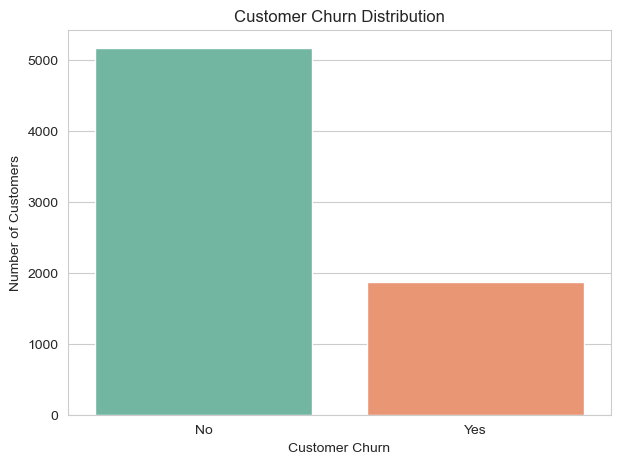

In [18]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Churn Percentage:")
print(churn_percentage.round(2))

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [22]:
# Remove customer ID
df.drop("customerID", axis=1, inplace=True)

# Convert TotalCharges into numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values
print("Missing values after conversion:")
print(df.isnull().sum())

# Separate input features and target
X = df.drop("Churn", axis=1)

# Convert target into binary values
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Missing values after conversion:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [24]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (5634, 19)
Testing Data: (1409, 19)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [28]:
# Numerical preprocessing
numeric_transformer = SklearnPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = SklearnPipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [30]:
print("Before SMOTE:")

print(y_train.value_counts())

print("\nClass Distribution Percentage:")

print((y_train.value_counts(normalize=True) * 100).round(2))

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

Class Distribution Percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [34]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("smote", SMOTE(random_state=42)),

        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=15,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train Random Forest
rf_model.fit(X_train, y_train)

# Predictions
rf_predictions = rf_model.predict(X_test)

# Probability predictions
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [36]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("smote", SMOTE(random_state=42)),

        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train XGBoost
xgb_model.fit(X_train, y_train)

# Predictions
xgb_predictions = xgb_model.predict(X_test)

# Probability predictions
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [38]:
ensemble_model = VotingClassifier(
    estimators=[
        ("rf", rf_model),
        ("xgb", xgb_model)
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

# Train ensemble
ensemble_model.fit(X_train, y_train)

# Predictions
ensemble_predictions = ensemble_model.predict(X_test)

# Probability predictions
ensemble_probabilities = ensemble_model.predict_proba(X_test)[:, 1]

print("Ensemble Model Trained Successfully!")

Ensemble Model Trained Successfully!


In [40]:
models = {
    "Random Forest": (rf_predictions, rf_probabilities),
    "XGBoost": (xgb_predictions, xgb_probabilities),
    "Ensemble": (ensemble_predictions, ensemble_probabilities)
}

results = []

for model_name, (predictions, probabilities) in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7729,0.5637,0.6390,0.5990,0.8322
1,XGBoost,0.7857,0.5933,0.6123,0.6026,0.8355
2,Ensemble,0.7786,0.5764,0.6257,0.6000,0.8360


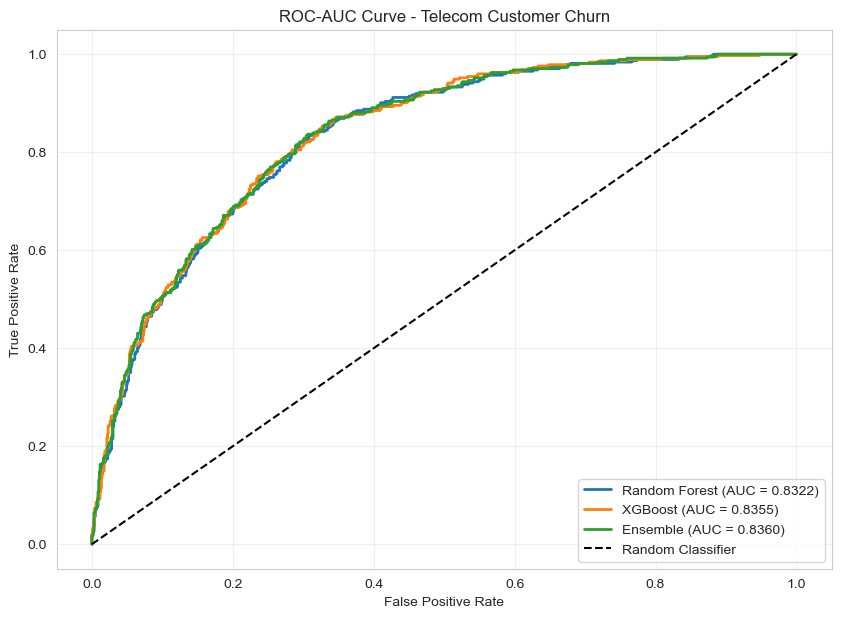

In [42]:
plt.figure(figsize=(10, 7))

for model_name, (predictions, probabilities) in models.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Curve - Telecom Customer Churn")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.show()

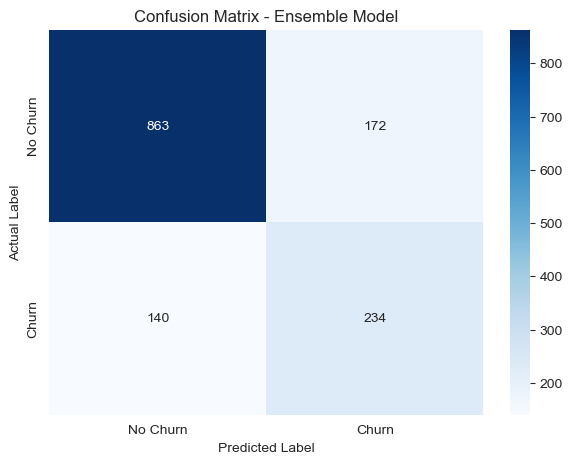

In [44]:
cm = confusion_matrix(
    y_test,
    ensemble_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Confusion Matrix - Ensemble Model")

plt.show()

In [46]:
print("Ensemble Model Classification Report")

print(
    classification_report(
        y_test,
        ensemble_predictions,
        target_names=["No Churn", "Churn"]
    )
)

Ensemble Model Classification Report
              precision    recall  f1-score   support

    No Churn       0.86      0.83      0.85      1035
       Churn       0.58      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



In [48]:
# Get trained preprocessor
rf_preprocessor = rf_model.named_steps["preprocessor"]

# Get encoded feature names
feature_names = rf_preprocessor.get_feature_names_out()

# Extract importance
rf_importances = rf_model.named_steps[
    "classifier"
].feature_importances_

# Create importance dataframe
rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
})

# Sort descending
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Top 10
top10_rf = rf_feature_importance.head(10)

display(top10_rf)

,Feature,Importance
36,cat__Contract_Month-to-month,0.112563
1,num__tenure,0.097408
3,num__TotalCharges,0.081165
18,cat__OnlineSecurity_No,0.069023
2,num__MonthlyCharges,0.063914
43,cat__PaymentMethod_Electronic check,0.060340
38,cat__Contract_Two year,0.047799
27,cat__TechSupport_No,0.047506
16,cat__InternetService_Fiber optic,0.031448
40,cat__PaperlessBilling_Yes,0.024463


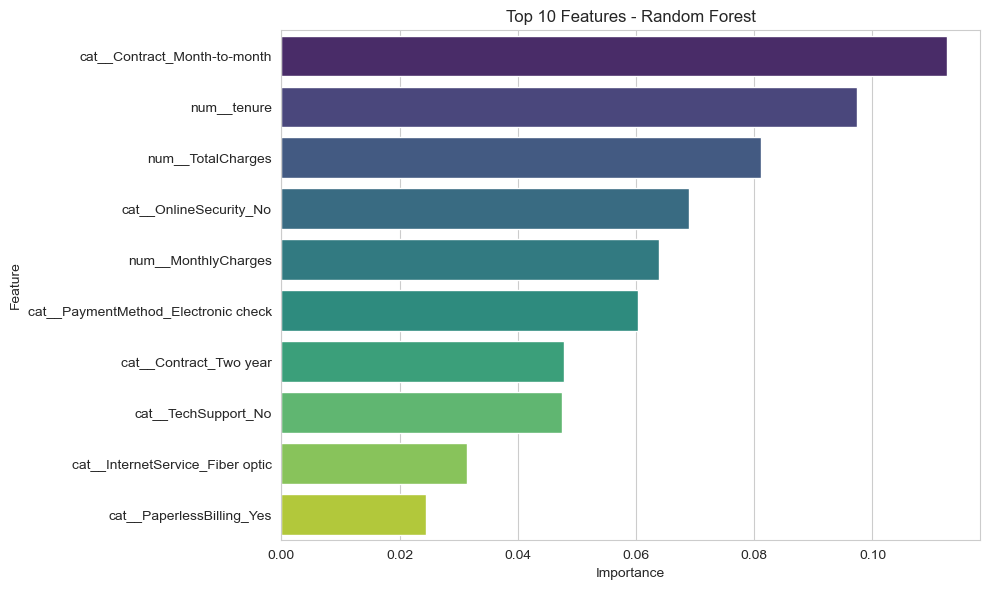

In [50]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10_rf,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Features - Random Forest")

plt.tight_layout()

plt.show()

In [52]:
# Get feature names
xgb_feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract importance
xgb_importances = xgb_model.named_steps[
    "classifier"
].feature_importances_

# Create dataframe
xgb_feature_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_importances
})

# Sort descending
xgb_feature_importance = xgb_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Top 10
top10_xgb = xgb_feature_importance.head(10)

display(top10_xgb)

,Feature,Importance
36,cat__Contract_Month-to-month,0.299318
18,cat__OnlineSecurity_No,0.076410
16,cat__InternetService_Fiber optic,0.074006
43,cat__PaymentMethod_Electronic check,0.045609
27,cat__TechSupport_No,0.030479
38,cat__Contract_Two year,0.026936
40,cat__PaperlessBilling_Yes,0.025467
9,cat__Dependents_Yes,0.025094
13,cat__MultipleLines_No phone service,0.024660
37,cat__Contract_One year,0.021788


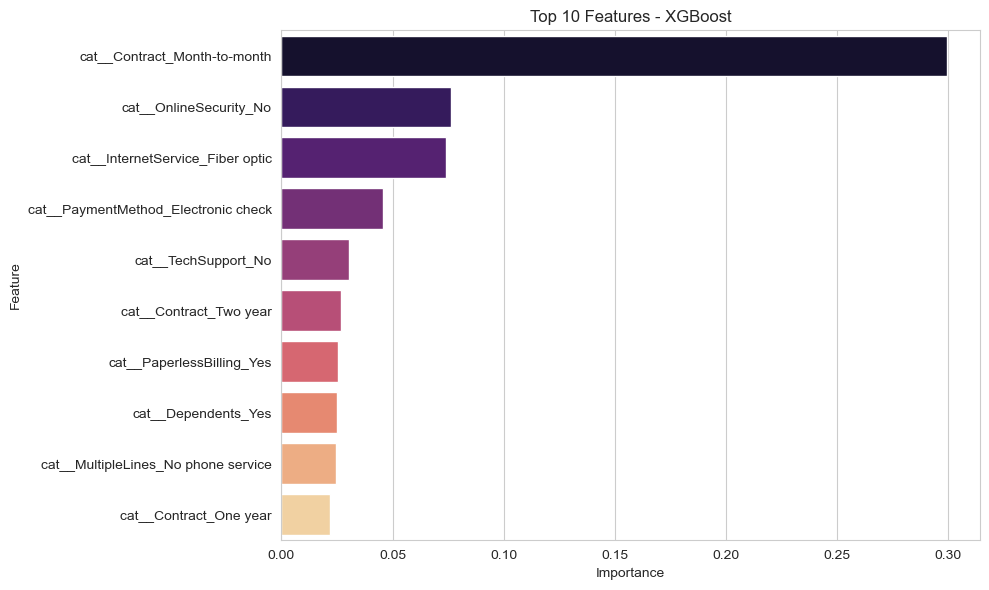

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10_xgb,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="magma",
    legend=False
)

plt.title("Top 10 Features - XGBoost")

plt.tight_layout()

plt.show()

In [59]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest CV
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1
)

# XGBoost CV
xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1
)

print("Random Forest CV Scores:")
print(rf_cv_scores)

print("Random Forest Mean ROC-AUC:", rf_cv_scores.mean())

print("\nXGBoost CV Scores:")
pri
nt(xgb_cv_scores)

print("XGBoost Mean ROC-AUC:", xgb_cv_scores.mean())

Random Forest CV Scores:
[0.82653531 0.8251438  0.83537718 0.8355226  0.85038803]
Random Forest Mean ROC-AUC: 0.8345933837604942

XGBoost CV Scores:
[0.82809647 0.82532354 0.83900037 0.84739389 0.84866928]
XGBoost Mean ROC-AUC: 0.837696712161377


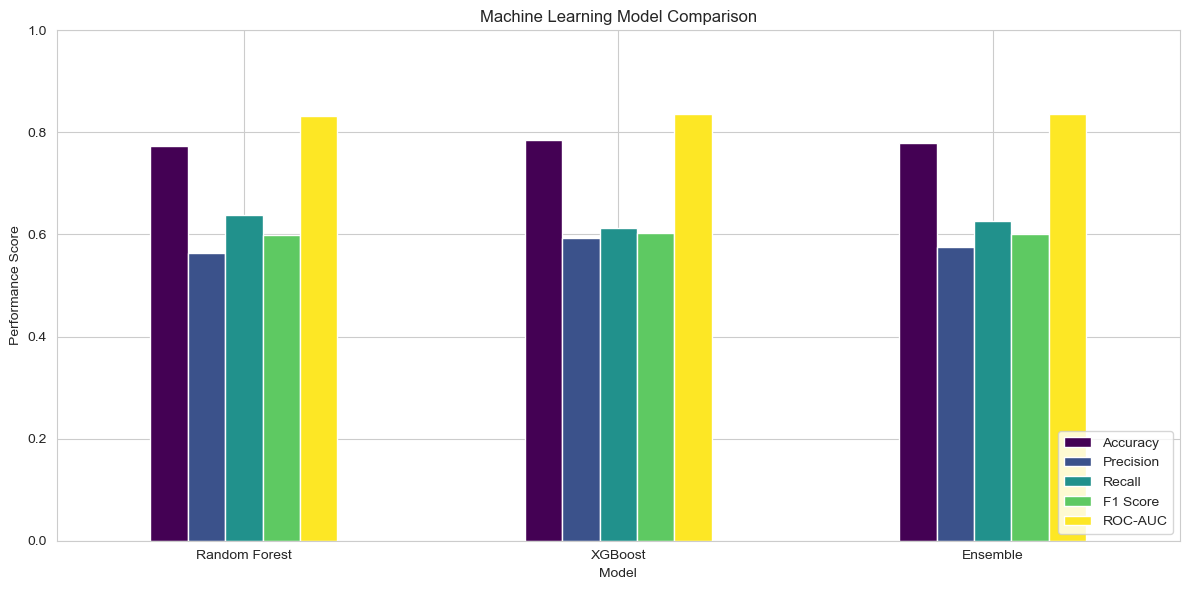

In [63]:
results_plot = results_df.set_index("Model")

results_plot[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    
    kind="bar",
    figsize=(12, 6),
    colormap="viridis"
)

plt.title("Machine Learning Model Comparison")

plt.ylabel("Performance Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

In [68]:
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 5,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.5,
    "TotalCharges": 427.5
}])

prediction = ensemble_model.predict(new_customer)

probability = ensemble_model.predict_proba(
    new_customer
)[0][1]

if prediction[0] == 1:
    print("Customer is likely to CHURN")
else:
    print("Customer is likely to STAY")

print("Churn Probability:", round(probability * 100, 2), "%")

Customer is likely to CHURN
Churn Probability: 87.29 %


In [70]:
joblib.dump(
    rf_model,
    "random_forest_churn_model.pkl"
)

joblib.dump(
    xgb_model,
    "xgboost_churn_model.pkl"
)

joblib.dump(
    ensemble_model,
    "ensemble_churn_model.pkl"
)

print("All models saved successfully!")

All models saved successfully!


In [72]:
results_df.to_csv(
    "model_performance.csv",
    index=False
)

top10_rf.to_csv(
    "random_forest_top10_features.csv",
    index=False
)

top10_xgb.to_csv(
    "xgboost_top10_features.csv",
    index=False
)

print("All results exported successfully!")

All results exported successfully!
